# Week 9 – Multivariate Analysis, Part 2

**Contents**
1. Lesson – *no lesson this week*
2. Weekly graph question (PCA scores of three synthetic series)
3. Project dataset analysis – **Breast Cancer Wisconsin (Diagnostic)** healthcare dataset (Kaggle / UCI)
   heatmaps, bubble plots, PCA, 1‑D PCA representation, outliers, linear regression, conclusions
4. *Storytelling With Data* plot – "The power of super‑categories" (Chapter 5)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import decomposition
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split, cross_val_score

pd.set_option("display.precision", 3)
pd.set_option("display.width", 140)
plt.rcParams["figure.dpi"] = 100

## 1. Lesson
No lesson this week.

## 2. Weekly graph question

The code below (as given) builds three series, centers them, runs PCA and plots the first two principal component scores.

[0.79916477 0.18990532 0.01092991]
[[ 0.26541493  0.30096233  0.91595665]
 [ 0.60337553  0.6891417  -0.40127506]
 [ 0.75199261 -0.65917023 -0.00131519]]


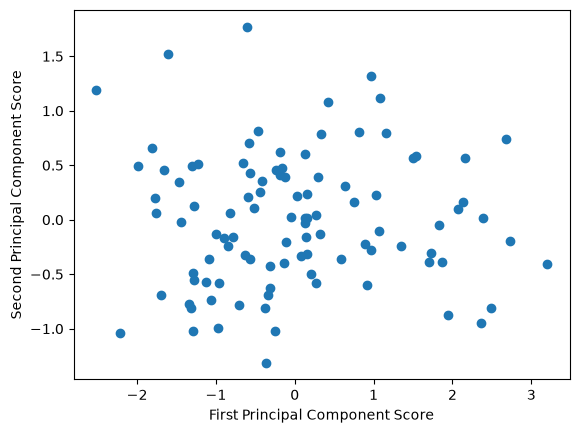

In [2]:
np.random.seed(0)
num_points = 100
series_1 = np.random.normal(loc = 2, scale = 0.5, size = num_points)
series_2 = series_1 * (1 + np.random.normal(loc = 0, scale = 0.1, size = num_points))
series_3 = series_1 * (1 + np.random.normal(loc = 0, scale = 0.5, size = num_points))
raw = pd.DataFrame({'ser1': series_1, 'ser2': series_2, 'ser3': series_3})
df = raw - raw.mean() # set mean to zero, so we don't have to subtract mean from the principal component scores

pca3 = decomposition.PCA(n_components = 3)
pca3.fit(df)
print(pca3.explained_variance_ratio_)
print(pca3.components_)

first_principal_component_score = df.dot(pca3.components_[0])
second_principal_component_score = df.dot(pca3.components_[1])
plt.scatter(first_principal_component_score, second_principal_component_score)
plt.xlabel("First Principal Component Score")
plt.ylabel("Second Principal Component Score")
plt.show()

### Identify the three upper‑left outliers
Upper left means **PC1 score < 0** and a **large PC2 score**. Let's pull them out and look at their original values.

In [3]:
scores = pd.DataFrame({'pc1': first_principal_component_score,
                       'pc2': second_principal_component_score,
                       'pc3': df.dot(pca3.components_[2])})
upper_left = scores[(scores.pc1 < 0) & (scores.pc2 > 1)]
print("Means of the raw series:", raw.mean().round(2).to_dict())
pd.concat([upper_left, raw.loc[upper_left.index]], axis=1)

Means of the raw series: {'ser1': 2.03, 'ser2': 2.05, 'ser3': 1.99}


,pc1,pc2,pc3,ser1,ser2,ser3
24,-0.608,1.772,0.263,3.135,2.917,0.720
37,-1.604,1.520,0.106,2.601,2.547,-0.091
71,-2.519,1.192,-0.022,2.064,2.130,-0.798


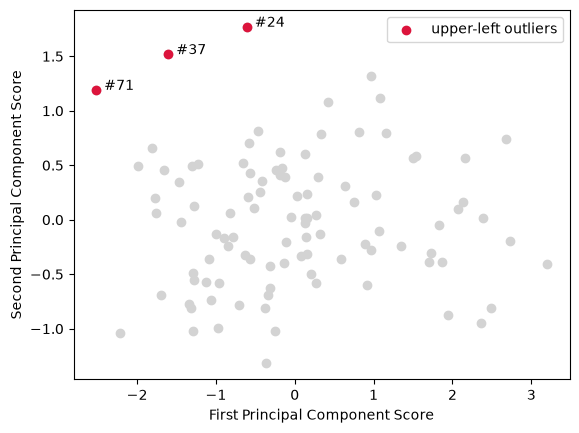

In [4]:
plt.scatter(scores.pc1, scores.pc2, color="lightgray")
plt.scatter(upper_left.pc1, upper_left.pc2, color="crimson", label="upper-left outliers")
for i in upper_left.index:
    plt.annotate(f"  #{i}", (upper_left.pc1[i], upper_left.pc2[i]))
plt.xlabel("First Principal Component Score"); plt.ylabel("Second Principal Component Score")
plt.legend(); plt.show()

### Pairplot of the three series (outliers highlighted)

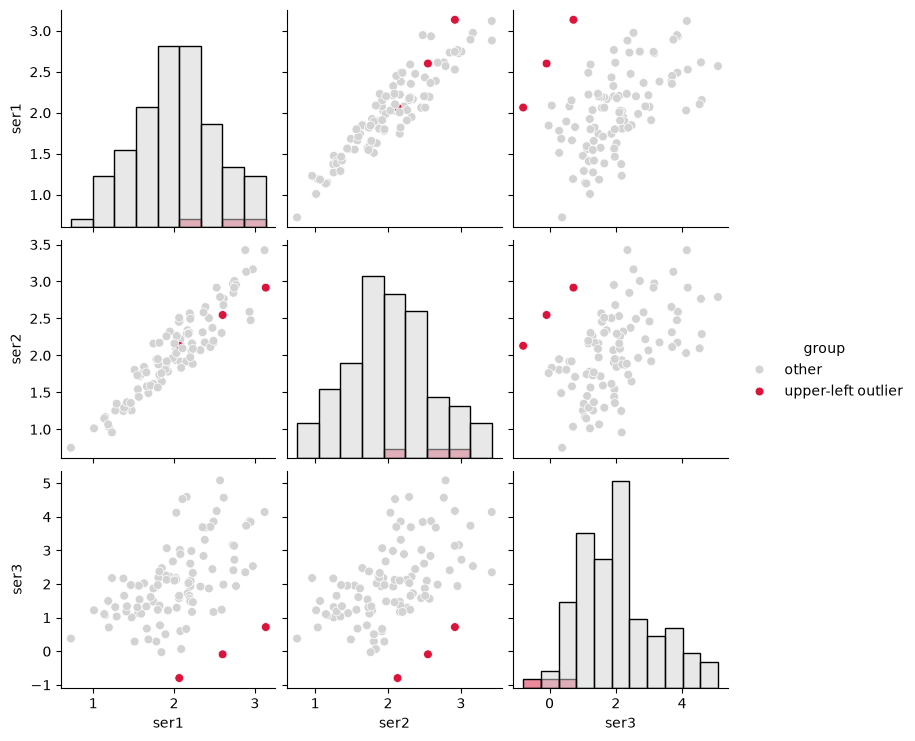

       ser1   ser2   ser3
ser1  1.000  0.926  0.488
ser2  0.926  1.000  0.490
ser3  0.488  0.490  1.000


In [5]:
pp = raw.copy()
pp["group"] = np.where(pp.index.isin(upper_left.index), "upper-left outlier", "other")
sns.pairplot(pp, hue="group", palette={"other": "lightgray", "upper-left outlier": "crimson"},
             plot_kws={"s": 40}, diag_kind="hist")
plt.show()
print(raw.corr())

### Answer

**Reading the loadings**

| | ser1 | ser2 | ser3 |
|---|---|---|---|
| PC1 (79.9 % of variance) | 0.27 | 0.30 | **0.92** |
| PC2 (19.0 %) | 0.60 | 0.69 | **−0.40** |
| PC3 (1.1 %) | 0.75 | −0.66 | 0.00 |

* **PC1 score is low (negative).** PC1 is dominated by `series_3` (weight 0.92) because `series_3` has by far the largest variance (its noise is 50 % multiplicative, std ≈ 1.17 vs ≈ 0.5 for the others). A low PC1 score therefore mostly means **`series_3` is well below its mean**.
* **PC2 score is high (positive).** PC2 is a *contrast*: (ser1 + ser2) versus ser3. A high PC2 means **ser1 and ser2 are high relative to ser3**.
* **Series_3:** both clues point the same way — PC1 low *and* the negative ser3 weight in PC2 — so we can confidently say the three points have **very low `series_3`** (in the data: 0.72, −0.09 and −0.80 vs a mean of ≈ 2.0; two are even negative). These are the points where the random factor `(1 + N(0, 0.5))` happened to be near or below zero.
* **Series_1 and series_2:** here the clues *conflict*. Low PC1 pulls ser1/ser2 down (small positive weights), high PC2 pulls them up. The net effect is "somewhere from average to above average" (actual ser1 values: 3.14, 2.60, 2.06 vs mean 2.03), but you can't read it reliably from the graph.
* **Series_1 vs series_2 (relative):** essentially impossible. The only direction that separates them is **PC3** = 0.75·ser1 − 0.66·ser2, which is *not plotted* and holds only 1.1 % of the variance. Both PC1 and PC2 weight ser1 and ser2 almost equally, so the graph cannot tell them apart.

**Why?** By construction `series_2 = series_1 × (1 + N(0, 0.1))` – it is just `series_1` with ±10 % noise, so they are almost the same variable (correlation ≈ 0.93). PCA merges them into one "ser1/ser2 together" direction; their small difference ends up in the last, tiny component. `series_3 = series_1 × (1 + N(0, 0.5))` shares the same underlying `series_1` but with large noise, so it's only moderately correlated (≈ 0.49) and carries its own big chunk of variance. The pairplot confirms this: ser1 vs ser2 is a tight line, while anything vs ser3 is a wide fan, and the red outliers sit at the bottom of the ser3 axis.

**Advantages of the graph**
* Compresses 3 variables into 2 axes while keeping ≈ 99 % of the variance – nearly nothing is lost.
* Makes multivariate outliers jump out (the upper‑left trio), which a single‑variable histogram might not reveal as clearly.
* Uncorrelated axes, so the scatter isn't dominated by the obvious ser1/ser2 redundancy.

**Disadvantages**
* The axes have no direct physical meaning; you need the loadings table to interpret anything, and interpretations can be ambiguous (as with ser1/ser2 here).
* Data were only centered, not standardized, so PC1 is driven by whichever series has the largest variance (ser3) rather than by "importance".
* Information in PC3 (the ser1‑vs‑ser2 difference) is invisible.
* No labels, title, or annotations of the outliers.

**Does it show anything interesting?** Yes – it shows the data are essentially **two‑dimensional** (a "ser1≈ser2" factor and a "ser3" factor) and flags a handful of points where `series_3` collapsed toward zero or below, i.e. where the 50 % noise factor produced extreme values. That's a real feature of the generating process, not a fluke of plotting.

## 3. Project dataset: Breast Cancer Wisconsin (Diagnostic)

**Source:** Kaggle – *Breast Cancer Wisconsin (Diagnostic) Data Set* (`uciml/breast-cancer-wisconsin-data`), originally from the UCI Machine Learning Repository (Wolberg, Street & Mangasarian, 1995; described in Street et al., *Proc. SPIE* 1993). It is one of the most widely used healthcare datasets on Kaggle. The identical data ship with scikit‑learn, so no download or Kaggle login is needed.

**What it is:** 569 fine‑needle aspirate (FNA) images of breast masses. For each image, 10 nucleus features are measured (radius, texture, perimeter, area, smoothness, compactness, concavity, concave points, symmetry, fractal dimension), and for each feature the **mean**, **standard error** and **worst** (largest) value are recorded → 30 numeric features + diagnosis (malignant / benign).

In [6]:
bc = load_breast_cancer(as_frame=True)
data = bc.frame.copy()
# sklearn codes 0 = malignant, 1 = benign; make it readable
data["diagnosis"] = data["target"].map({0: "Malignant", 1: "Benign"})
data = data.drop(columns="target")
features = bc.feature_names.tolist()
mean_feats = [f for f in features if f.startswith("mean")]
print(data.shape)
print(data["diagnosis"].value_counts())
print("Missing values:", data.isna().sum().sum())
data.head()

(569, 31)
diagnosis
Benign       357
Malignant    212
Name: count, dtype: int64
Missing values: 0


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnosis
0,17.99,10.38,122.80,1001.0,0.118,0.278,0.300,0.147,0.242,0.079,...,17.33,184.60,2019.0,0.162,0.666,0.712,0.265,0.460,0.119,Malignant
1,20.57,17.77,132.90,1326.0,0.085,0.079,0.087,0.070,0.181,0.057,...,23.41,158.80,1956.0,0.124,0.187,0.242,0.186,0.275,0.089,Malignant
2,19.69,21.25,130.00,1203.0,0.110,0.160,0.197,0.128,0.207,0.060,...,25.53,152.50,1709.0,0.144,0.424,0.450,0.243,0.361,0.088,Malignant
3,11.42,20.38,77.58,386.1,0.142,0.284,0.241,0.105,0.260,0.097,...,26.50,98.87,567.7,0.210,0.866,0.687,0.258,0.664,0.173,Malignant
4,20.29,14.34,135.10,1297.0,0.100,0.133,0.198,0.104,0.181,0.059,...,16.67,152.20,1575.0,0.137,0.205,0.400,0.163,0.236,0.077,Malignant


In [7]:
data[mean_feats].describe().T

,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127,3.524,6.981,11.700,13.370,15.780,28.110
mean texture,569.0,19.290,4.301,9.710,16.170,18.840,21.800,39.280
mean perimeter,569.0,91.969,24.299,43.790,75.170,86.240,104.100,188.500
mean area,569.0,654.889,351.914,143.500,420.300,551.100,782.700,2501.000
mean smoothness,569.0,0.096,0.014,0.053,0.086,0.096,0.105,0.163
mean compactness,569.0,0.104,0.053,0.019,0.065,0.093,0.130,0.345
mean concavity,569.0,0.089,0.080,0.000,0.030,0.062,0.131,0.427
mean concave points,569.0,0.049,0.039,0.000,0.020,0.034,0.074,0.201
mean symmetry,569.0,0.181,0.027,0.106,0.162,0.179,0.196,0.304
mean fractal dimension,569.0,0.063,0.007,0.050,0.058,0.062,0.066,0.097


### 3.1 Heatmaps
First, the correlation matrix of the 10 "mean" features; then the full 30‑feature matrix.

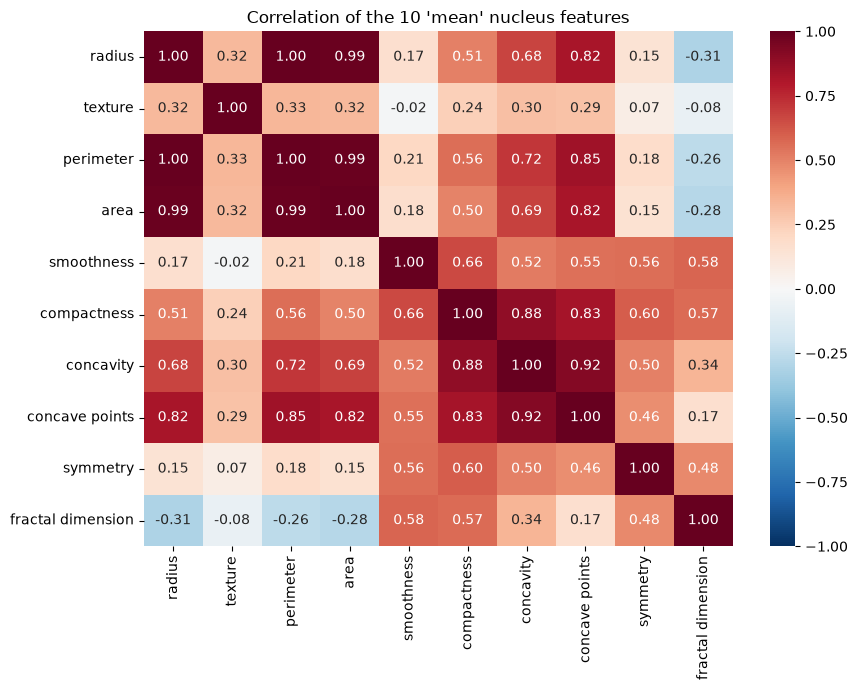

In [8]:
corr_mean = data[mean_feats].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr_mean, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
            xticklabels=[c.replace("mean ", "") for c in mean_feats],
            yticklabels=[c.replace("mean ", "") for c in mean_feats])
plt.title("Correlation of the 10 'mean' nucleus features")
plt.tight_layout(); plt.show()

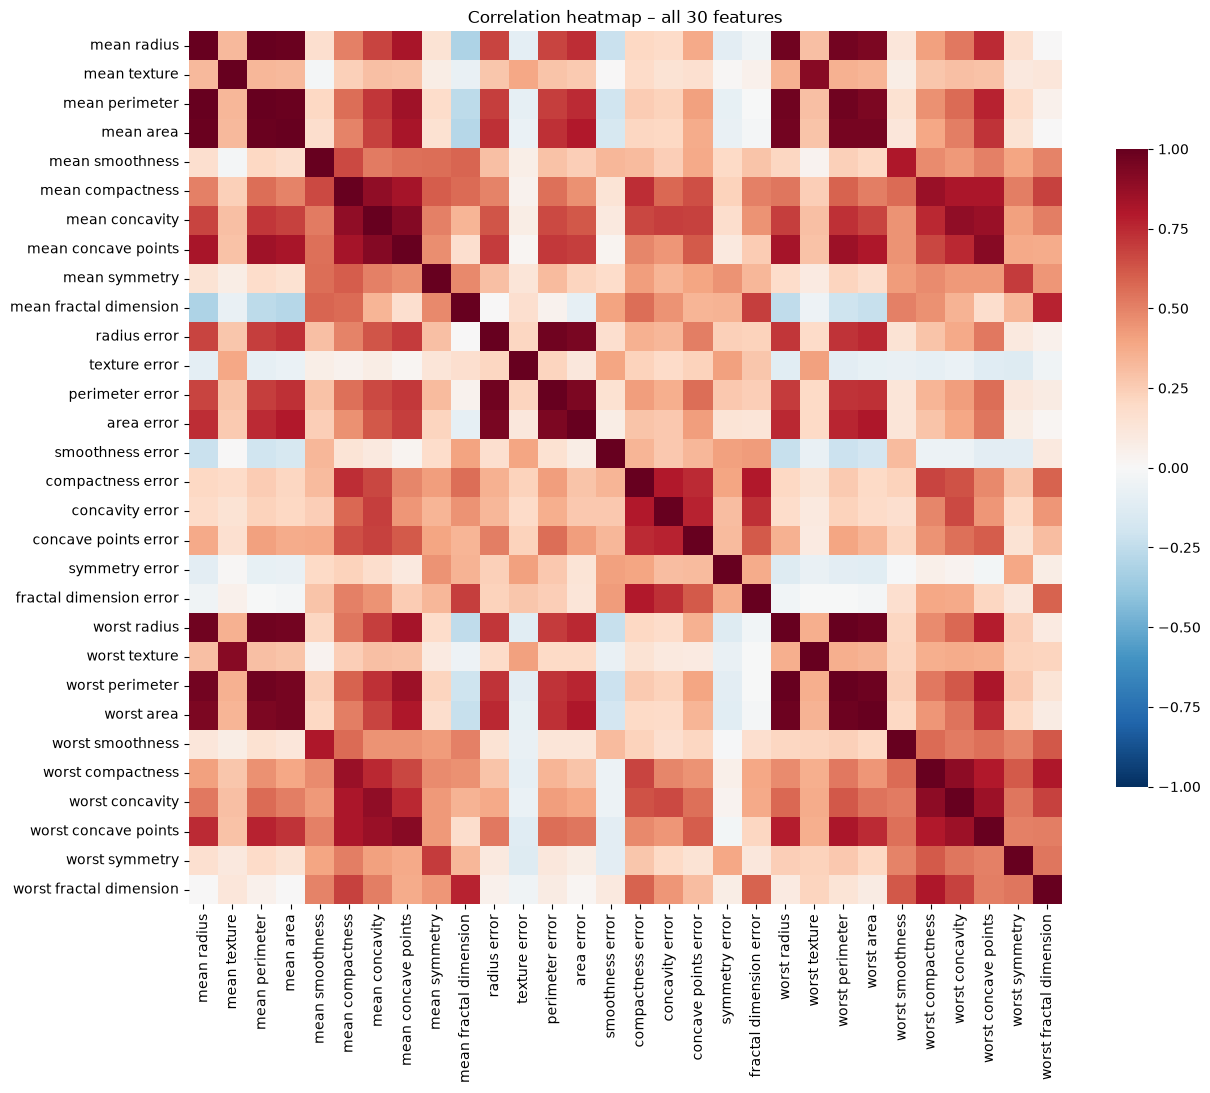

In [9]:
plt.figure(figsize=(13, 11))
sns.heatmap(data[features].corr(), cmap="RdBu_r", vmin=-1, vmax=1, square=True,
            cbar_kws={"shrink": .7})
plt.title("Correlation heatmap – all 30 features")
plt.tight_layout(); plt.show()

A second kind of heatmap: **standardized feature means by diagnosis** – shows which features differ most between malignant and benign tumors.

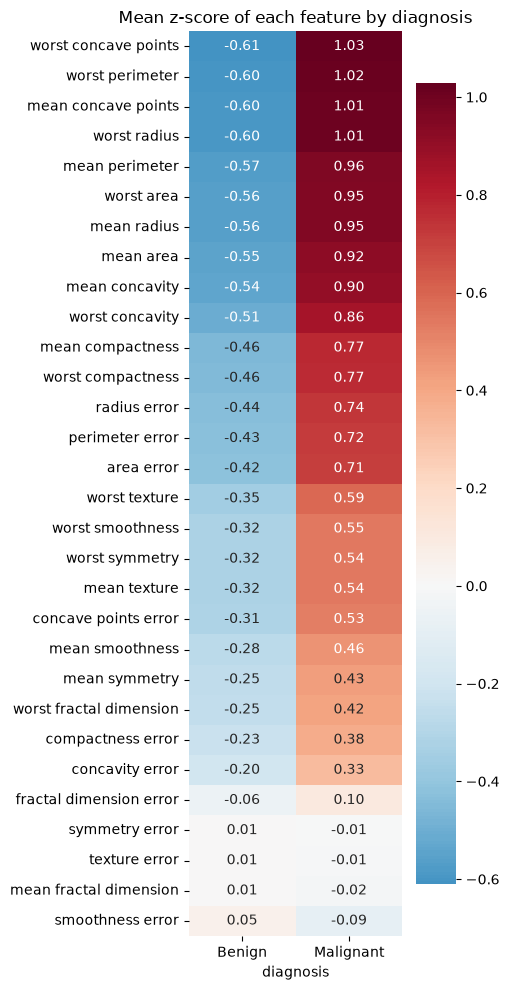

In [10]:
z = (data[features] - data[features].mean()) / data[features].std()
z["diagnosis"] = data["diagnosis"]
group_profile = z.groupby("diagnosis").mean().T
group_profile = group_profile.sort_values("Malignant", ascending=False)
plt.figure(figsize=(5, 10))
sns.heatmap(group_profile, annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Mean z-score of each feature by diagnosis")
plt.tight_layout(); plt.show()

### 3.2 Bubble plots
x = mean radius, y = mean texture, bubble size = mean area, colour = diagnosis. A second bubble plot uses concavity and concave points.

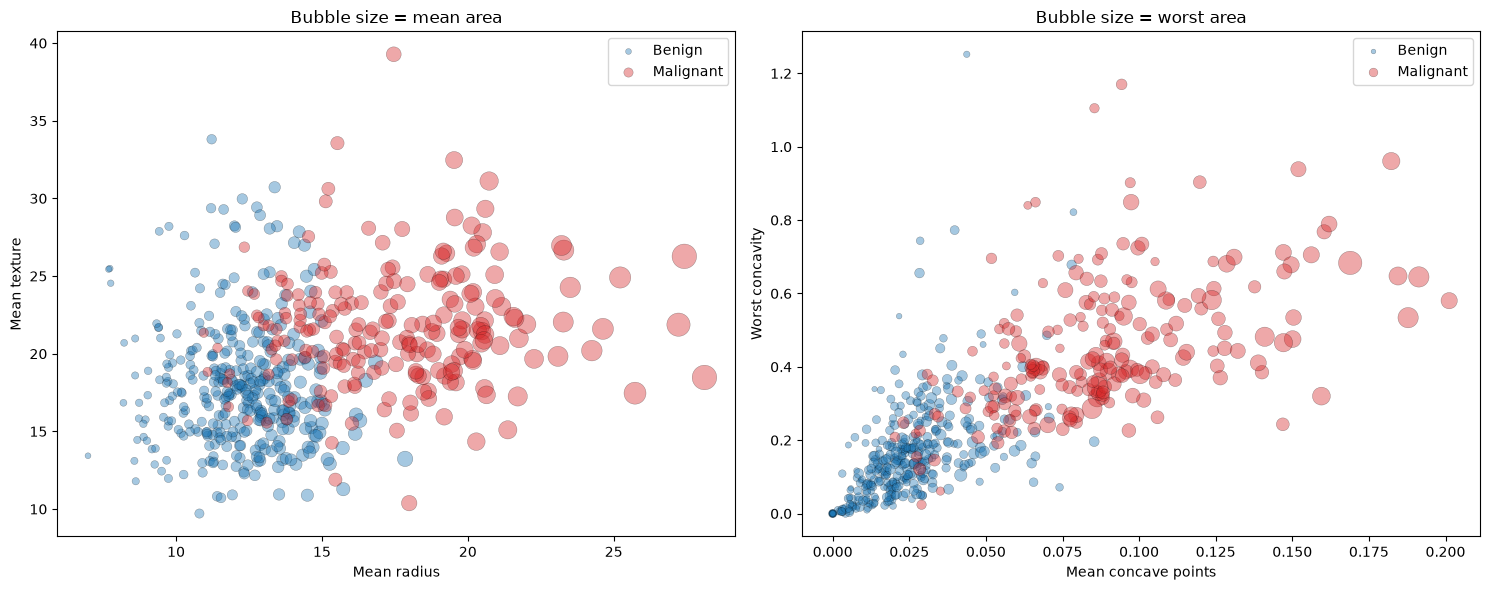

In [11]:
colors = {"Benign": "tab:blue", "Malignant": "tab:red"}
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for dx, grp in data.groupby("diagnosis"):
    axes[0].scatter(grp["mean radius"], grp["mean texture"], s=grp["mean area"] / 8,
                    alpha=0.4, color=colors[dx], edgecolor="k", linewidth=0.3, label=dx)
    axes[1].scatter(grp["mean concave points"], grp["worst concavity"], s=grp["worst area"] / 15,
                    alpha=0.4, color=colors[dx], edgecolor="k", linewidth=0.3, label=dx)
axes[0].set(xlabel="Mean radius", ylabel="Mean texture",
            title="Bubble size = mean area")
axes[1].set(xlabel="Mean concave points", ylabel="Worst concavity",
            title="Bubble size = worst area")
for ax in axes:
    ax.legend(markerscale=0.5)
plt.tight_layout(); plt.show()

### 3.3 Principal Component Analysis
The features are on very different scales (area is in the hundreds/thousands, fractal dimension ≈ 0.06), so we **standardize** first; otherwise `area` alone would dominate PC1.

Explained variance ratio (first 10): [0.443 0.19  0.094 0.066 0.055 0.04  0.023 0.016 0.014 0.012]
Cumulative: [0.443 0.632 0.726 0.792 0.847 0.888 0.91  0.926 0.94  0.952]
Components needed for 90% variance: 7
Components needed for 95% variance: 10


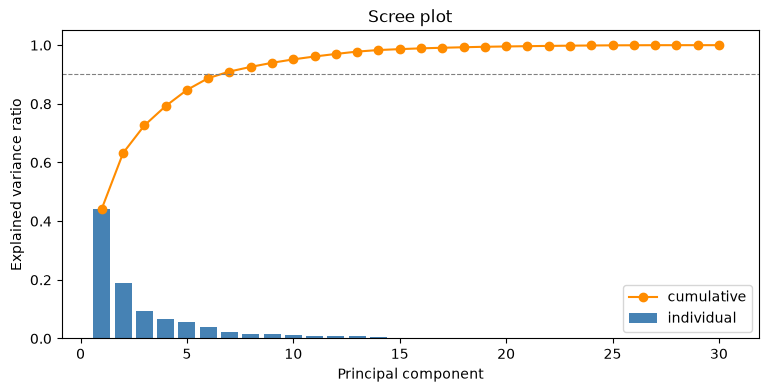

In [12]:
X = data[features]
scaler = StandardScaler()
Xs = scaler.fit_transform(X)

pca = decomposition.PCA()
pca.fit(Xs)
evr = pca.explained_variance_ratio_
print("Explained variance ratio (first 10):", evr[:10].round(3))
print("Cumulative:", np.cumsum(evr)[:10].round(3))
print("Components needed for 90% variance:", np.argmax(np.cumsum(evr) >= 0.90) + 1)
print("Components needed for 95% variance:", np.argmax(np.cumsum(evr) >= 0.95) + 1)

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(range(1, 31), evr, color="steelblue", label="individual")
ax.plot(range(1, 31), np.cumsum(evr), "o-", color="darkorange", label="cumulative")
ax.axhline(0.9, ls="--", color="gray", lw=0.8)
ax.set(xlabel="Principal component", ylabel="Explained variance ratio", title="Scree plot")
ax.legend(); plt.show()

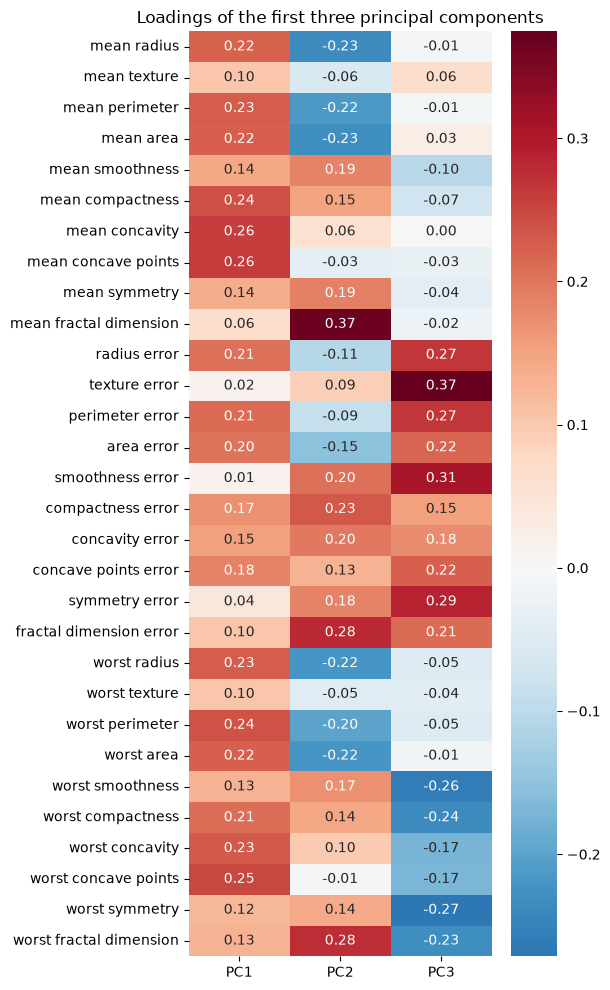

Top PC1 loadings:
 mean concave points     0.261
mean concavity          0.258
worst concave points    0.251
mean compactness        0.239
worst perimeter         0.237
worst concavity         0.229
Name: PC1, dtype: float64

Top PC2 loadings:
 mean radius               -0.234
mean area                 -0.231
worst radius              -0.220
worst fractal dimension    0.275
fractal dimension error    0.280
mean fractal dimension     0.367
Name: PC2, dtype: float64


In [13]:
loadings = pd.DataFrame(pca.components_[:3].T, index=features, columns=["PC1", "PC2", "PC3"])
plt.figure(figsize=(6, 10))
sns.heatmap(loadings, annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Loadings of the first three principal components")
plt.tight_layout(); plt.show()
print("Top PC1 loadings:\n", loadings["PC1"].abs().sort_values(ascending=False).head(6))
print("\nTop PC2 loadings:\n", loadings["PC2"].sort_values().iloc[[0, 1, 2, -3, -2, -1]])

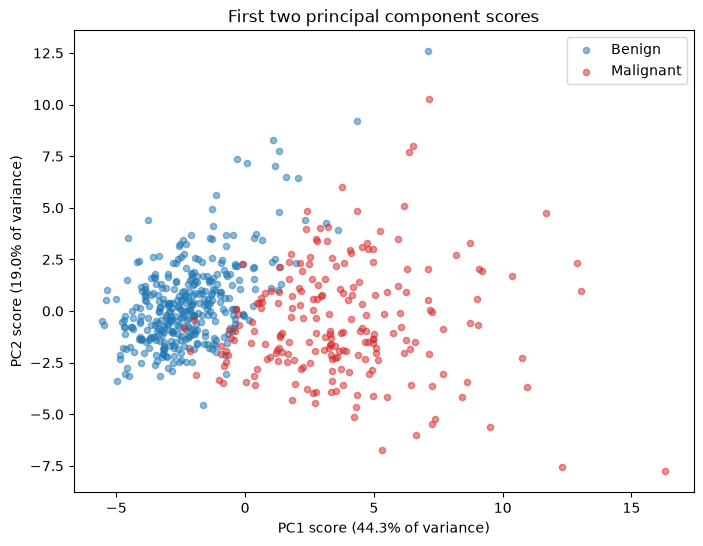

In [14]:
pc_scores = pca.transform(Xs)
data["PC1"], data["PC2"] = pc_scores[:, 0], pc_scores[:, 1]
plt.figure(figsize=(8, 6))
for dx, grp in data.groupby("diagnosis"):
    plt.scatter(grp.PC1, grp.PC2, alpha=0.5, color=colors[dx], label=dx, s=20)
plt.xlabel(f"PC1 score ({evr[0]:.1%} of variance)")
plt.ylabel(f"PC2 score ({evr[1]:.1%} of variance)")
plt.title("First two principal component scores")
plt.legend(); plt.show()

### 3.4 Representing the data with only its first principal component (Week 8 method)
Project each (standardized) point onto PC1, then reconstruct: $\hat{x} = \bar{x} + (x\cdot v_1)\,v_1$. The share of variance kept equals PC1's explained‑variance ratio; we verify that by comparing reconstruction error to total variance. We also try 2 and 5 components.

 1 component(s): variance captured = 0.443
 2 component(s): variance captured = 0.632
 3 component(s): variance captured = 0.726
 5 component(s): variance captured = 0.847
10 component(s): variance captured = 0.952


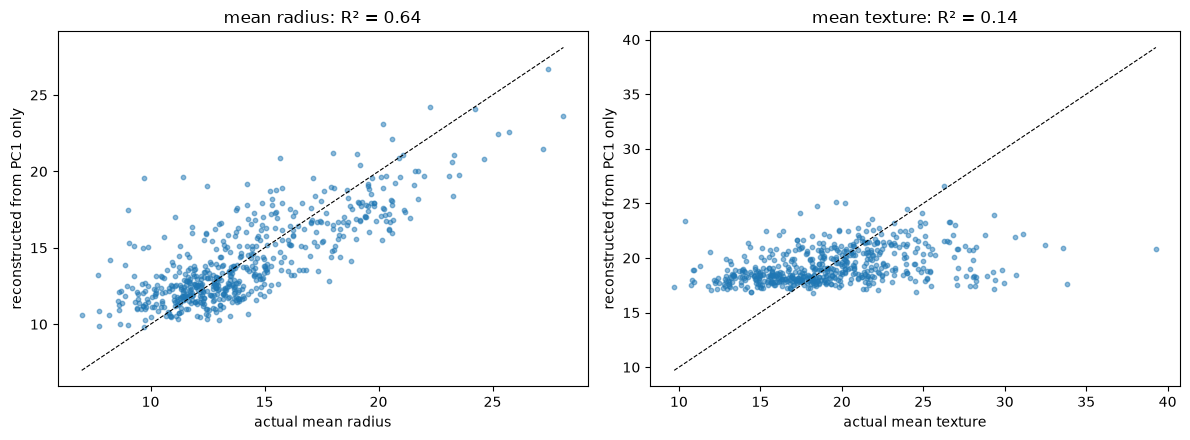

In [15]:
total_var = ((Xs - Xs.mean(axis=0)) ** 2).sum()
for k in [1, 2, 3, 5, 10]:
    V = pca.components_[:k]                     # k x 30
    proj = (Xs - pca.mean_) @ V.T               # scores
    recon = proj @ V + pca.mean_                # back in 30-D
    err = ((Xs - recon) ** 2).sum()
    print(f"{k:>2} component(s): variance captured = {1 - err / total_var:.3f}")

# 1-D representation in original units for one feature, for illustration
v1 = pca.components_[0]
recon1 = scaler.inverse_transform(((Xs - pca.mean_) @ v1)[:, None] * v1 + pca.mean_)
recon1 = pd.DataFrame(recon1, columns=features)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, f in zip(axes, ["mean radius", "mean texture"]):
    ax.scatter(data[f], recon1[f], s=10, alpha=0.5)
    lims = [data[f].min(), data[f].max()]
    ax.plot(lims, lims, "k--", lw=0.8)
    r2 = 1 - ((data[f] - recon1[f]) ** 2).sum() / ((data[f] - data[f].mean()) ** 2).sum()
    ax.set(xlabel=f"actual {f}", ylabel="reconstructed from PC1 only", title=f"{f}: R² = {r2:.2f}")
plt.tight_layout(); plt.show()

PC1 alone reconstructs the size features reasonably (mean radius R² ≈ 0.64) but texture poorly (R² ≈ 0.14), because texture loads mostly on other components. One dimension summarizes *how large and irregular* a tumor is (≈ 44 % of the variance), but not everything.

Can PC1 alone separate the diagnoses? A histogram of PC1 scores:

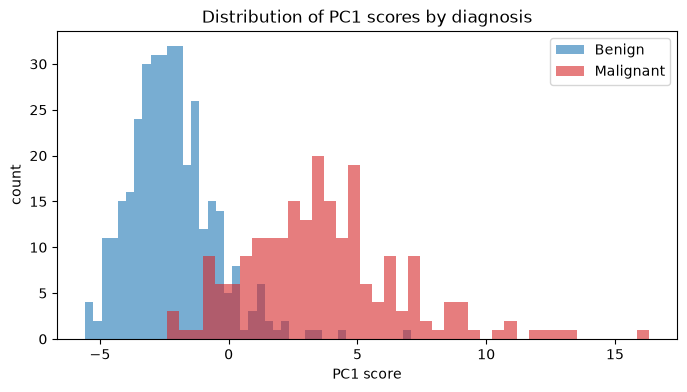

Simple rule 'PC1 > 0 => malignant' is correct for 91.6% of patients


In [16]:
plt.figure(figsize=(8, 4))
for dx, grp in data.groupby("diagnosis"):
    plt.hist(grp.PC1, bins=40, alpha=0.6, color=colors[dx], label=dx)
plt.xlabel("PC1 score"); plt.ylabel("count"); plt.legend()
plt.title("Distribution of PC1 scores by diagnosis"); plt.show()
acc = ((data.PC1 > 0) == (data.diagnosis == "Malignant")).mean()
print(f"Simple rule 'PC1 > 0 => malignant' is correct for {acc:.1%} of patients")

### 3.5 Outliers
Two approaches: (1) points with any |z| > 4 on a single feature, and (2) points far from the centre in PC space (squared distance using the first 10 standardized PC scores – a Mahalanobis‑type distance).

In [17]:
zabs = np.abs((X - X.mean()) / X.std())
single_out = (zabs > 4).sum(axis=1)
print("Rows with at least one |z| > 4:", (single_out > 0).sum())
print("Features most often extreme:\n", (zabs > 4).sum().sort_values(ascending=False).head(6))

k = 10
pcs = pca.transform(Xs)[:, :k] / np.sqrt(pca.explained_variance_[:k])
dist2 = (pcs ** 2).sum(axis=1)
from scipy.stats import chi2
cut = chi2.ppf(0.999, df=k)
data["pc_dist2"] = dist2
outliers = data[dist2 > cut]
print(f"\nMultivariate outliers (distance² > chi²_0.999,{k} = {cut:.1f}): {len(outliers)}")
outliers[["diagnosis", "mean radius", "mean area", "mean concavity", "worst area", "area error", "pc_dist2"]].sort_values("pc_dist2", ascending=False)

Rows with at least one |z| > 4: 34
Features most often extreme:
 symmetry error             5
texture error              4
area error                 4
fractal dimension error    4
smoothness error           4
mean fractal dimension     4
dtype: int64

Multivariate outliers (distance² > chi²_0.999,10 = 29.6): 24


,diagnosis,mean radius,mean area,mean concavity,worst area,area error,pc_dist2
212,Malignant,28.110,2499.0,0.320,2499.0,525.600,156.540
152,Benign,9.731,300.2,0.411,380.5,49.850,131.458
461,Malignant,27.420,2501.0,0.363,4254.0,542.200,119.924
213,Malignant,17.420,948.0,0.168,1021.0,58.530,113.131
68,Benign,9.029,250.5,0.313,324.7,17.670,103.712
192,Benign,9.720,288.1,0.000,303.8,21.690,80.728
71,Benign,8.888,244.0,0.086,284.4,25.440,73.594
78,Malignant,20.180,1245.0,0.375,1623.0,116.400,53.071
3,Malignant,11.420,386.1,0.241,567.7,27.230,52.719
12,Malignant,19.170,1123.0,0.206,1332.0,116.200,51.001


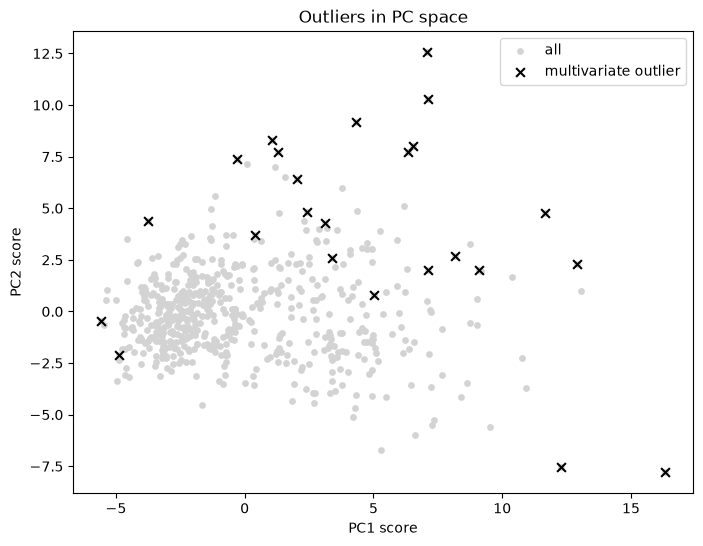

In [18]:
plt.figure(figsize=(8, 6))
plt.scatter(data.PC1, data.PC2, c="lightgray", s=15, label="all")
plt.scatter(outliers.PC1, outliers.PC2, c="black", s=40, marker="x", label="multivariate outlier")
plt.xlabel("PC1 score"); plt.ylabel("PC2 score"); plt.legend()
plt.title("Outliers in PC space"); plt.show()

### 3.6 Linear regression with different feature sets
The correlation heatmap tells us which features move together. Two targets are tried:

* **`worst area`** (the largest nucleus area) – a clinically important size measure.
* **`mean concavity`** – a shape measure, less trivially tied to size.

For each target we compare feature sets chosen with the correlation matrix (5‑fold cross‑validated R²). Note that `radius`, `perimeter` and `area` are geometrically linked (area ≈ πr²), so we deliberately avoid using the same quantity's other forms as predictors where that would be trivial.

In [19]:
corr_all = data[features].corr()
print("Strongest correlates of 'mean concavity':")
print(corr_all["mean concavity"].drop("mean concavity").sort_values(ascending=False).head(6))

Strongest correlates of 'mean concavity':
mean concave points     0.921
worst concavity         0.884
mean compactness        0.883
worst concave points    0.861
worst compactness       0.755
worst perimeter         0.730
Name: mean concavity, dtype: float64


In [20]:
def evaluate(target, feature_sets):
    rows = []
    y = data[target]
    for name, cols in feature_sets.items():
        r2 = cross_val_score(LinearRegression(), data[cols], y, cv=5, scoring="r2")
        rows.append({"target": target, "feature set": name, "n features": len(cols),
                     "CV R² mean": r2.mean(), "CV R² std": r2.std()})
    return pd.DataFrame(rows)

sets_area = {
    "mean radius only":                ["mean radius"],
    "mean texture only":               ["mean texture"],
    "mean radius + mean texture":      ["mean radius", "mean texture"],
    "shape features (no size)":        ["mean concavity", "mean concave points", "mean compactness",
                                        "mean smoothness", "mean symmetry"],
    "all 10 mean features":            mean_feats,
}
sets_concav = {
    "mean concave points only":        ["mean concave points"],
    "mean compactness only":           ["mean compactness"],
    "concave points + compactness":    ["mean concave points", "mean compactness"],
    "size only (radius, area)":        ["mean radius", "mean area"],
    "all other mean features":         [f for f in mean_feats if f != "mean concavity"],
}
results = pd.concat([evaluate("worst area", sets_area), evaluate("mean concavity", sets_concav)])
results

,target,feature set,n features,CV R² mean,CV R² std
0,worst area,mean radius only,1,0.881,0.014
1,worst area,mean texture only,1,0.079,0.122
2,worst area,mean radius + mean texture,2,0.882,0.017
3,worst area,shape features (no size),5,0.774,0.039
4,worst area,all 10 mean features,10,0.909,0.047
0,mean concavity,mean concave points only,1,0.848,0.032
1,mean concavity,mean compactness only,1,0.770,0.063
2,mean concavity,concave points + compactness,2,0.891,0.034
3,mean concavity,"size only (radius, area)",2,0.451,0.105
4,mean concavity,all other mean features,9,0.903,0.031


coefficients: {'mean concave points': np.float64(1.22), 'mean compactness': np.float64(0.581)} intercept: -0.0315
test R²: 0.923


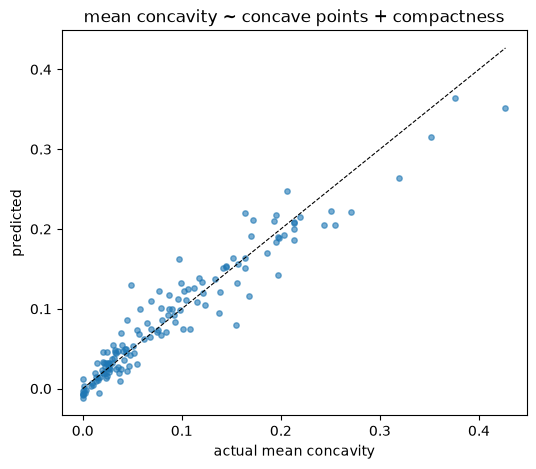

In [21]:
# Fit the best simple model on a train/test split and inspect it
Xtr, Xte, ytr, yte = train_test_split(data[["mean concave points", "mean compactness"]],
                                      data["mean concavity"], test_size=0.25, random_state=0)
lr = LinearRegression().fit(Xtr, ytr)
print("coefficients:", dict(zip(Xtr.columns, lr.coef_.round(3))), "intercept:", round(lr.intercept_, 4))
print("test R²:", round(lr.score(Xte, yte), 3))
plt.figure(figsize=(6, 5))
plt.scatter(yte, lr.predict(Xte), s=15, alpha=0.6)
lims = [0, data["mean concavity"].max()]
plt.plot(lims, lims, "k--", lw=0.8)
plt.xlabel("actual mean concavity"); plt.ylabel("predicted")
plt.title("mean concavity ~ concave points + compactness"); plt.show()

In [22]:
# Can principal component scores replace raw features as regression inputs?
y = data["mean concavity"]
other = [f for f in features if not f.endswith("concavity")]   # drop all concavity columns to avoid leakage
Xo = StandardScaler().fit_transform(data[other])
for k in [1, 2, 3, 5]:
    sc = decomposition.PCA(n_components=k).fit_transform(Xo)
    r2 = cross_val_score(LinearRegression(), sc, y, cv=5, scoring="r2").mean()
    print(f"mean concavity from first {k} PC score(s) of the other features: CV R² = {r2:.3f}")

mean concavity from first 1 PC score(s) of the other features: CV R² = 0.841
mean concavity from first 2 PC score(s) of the other features: CV R² = 0.874
mean concavity from first 3 PC score(s) of the other features: CV R² = 0.872
mean concavity from first 5 PC score(s) of the other features: CV R² = 0.886


### 3.7 Conclusions

**Are the data what we expect? Are they usable?**
Yes. There are 569 complete records (no missing values), 357 benign and 212 malignant. Every feature is in a plausible physical range. The structure matches what we know about the biology: malignant nuclei are **larger** (radius/area/perimeter) and **more irregular** (concavity, concave points, compactness). In the z‑score heatmap, malignant tumors sit about +0.8 to +1.0 SD above average on those features. The dataset is clean and well documented, so it is usable for this project.

**Correlations / heatmaps.** There are big blocks of near‑duplicate features. Radius, perimeter and area correlate above 0.98 (they are geometrically linked). Concavity, concave points and compactness correlate around 0.83 to 0.92. Each "mean" feature also tracks its "worst" counterpart. Texture, smoothness, symmetry and fractal dimension are much more independent. So the 30 columns contain far fewer than 30 independent pieces of information.

**PCA.** After standardizing:
* PC1 explains **44.3 %** of the variance. Its loadings are almost all positive (concave points, concavity, compactness, perimeter…), so it is an overall **"size + irregularity / severity"** score.
* PC2 adds **19.0 %** (63.2 % cumulative). It contrasts **fractal dimension / smoothness (+)** with **size (−)**: small but complex, jagged cells versus large ones.
* You need 7 components for 90 % of the variance and 10 for 95 %, out of 30.

**Representing the data with fewer dimensions.** Projecting onto PC1 alone keeps only 44 % of the total variance, so it is not a faithful reconstruction of all 30 features (texture especially is lost). For the *clinical question*, though, PC1 alone is remarkably useful: the rule "PC1 > 0 ⇒ malignant" classifies **91.6 %** of patients correctly, and the PC1/PC2 scatter shows two clearly separated clouds. Two PC scores give a good visual summary; about 5 PCs (85 % of variance) are a reasonable compact representation for modelling.

**Outliers.** 34 rows have at least one feature with |z| > 4, mostly in the noisy "error" (standard‑error) columns. In PC space, 24 rows exceed the 99.9 % χ² cutoff. The most extreme are very large malignant tumors (#212, #461: mean area ≈ 2,500, area error > 500) and a few small benign masses with unusually high concavity (#152, #68). Some benign rows have concavity exactly 0, which is probably a segmentation artifact rather than a real measurement. These points look like genuine extreme cases rather than data‑entry errors, so I would keep them but flag them. A robust model or a sensitivity check should test how much they matter.

**Linear regression (features chosen from the correlation matrix).**
* `worst area`: `mean radius` alone gives CV R² = 0.88. Adding texture adds nothing (texture alone: 0.08), which matches their weak correlation. All 10 mean features reach 0.91. Shape features *without any size measure* still get 0.77, because large tumors also tend to be irregular.
* `mean concavity`: its strongest correlates, concave points (r = 0.92) and compactness (0.88), give R² = 0.85 and 0.77 alone and **0.89 together** (0.92 on a held‑out test set). Size alone only gets 0.45. Using all other mean features barely improves on the 2‑feature model (0.90).
* The first PC score of the *other* features predicts concavity with R² = 0.84, and 5 PCs reach 0.89. So PC scores are a compact, non‑collinear substitute for many raw inputs.
* **Most useful predictors:** the size group (radius/perimeter/area) for size‑type targets, and concave points / compactness for shape targets. Because of the heavy multicollinearity, individual regression coefficients should not be over‑interpreted. Picking one feature per correlated block, or using PC scores, is the sensible approach.

**Overall:** the dataset is clean, behaves as expected, and is highly redundant. Two or three principal components capture the main story (tumor size/irregularity separates malignant from benign). It is a good choice for continued analysis, including classification in later weeks.

## 4. *Storytelling With Data* plot – "The power of super‑categories"

In Chapter 5 Knaflic shows that when a horizontal bar chart has many categories, **grouping them into a few super‑categories** (with a bold label and a light separator for each group) and **highlighting only the group that matters** turns a wall of bars into something the eye can scan. The rest of the look: no chart border, no gridlines, x‑axis removed in favour of direct data labels, grey for context, one strong accent colour, a left‑aligned action title, and explanatory text next to the data.

The version below keeps that look and feel with made‑up healthcare survey values ("What matters most when choosing a hospital?").

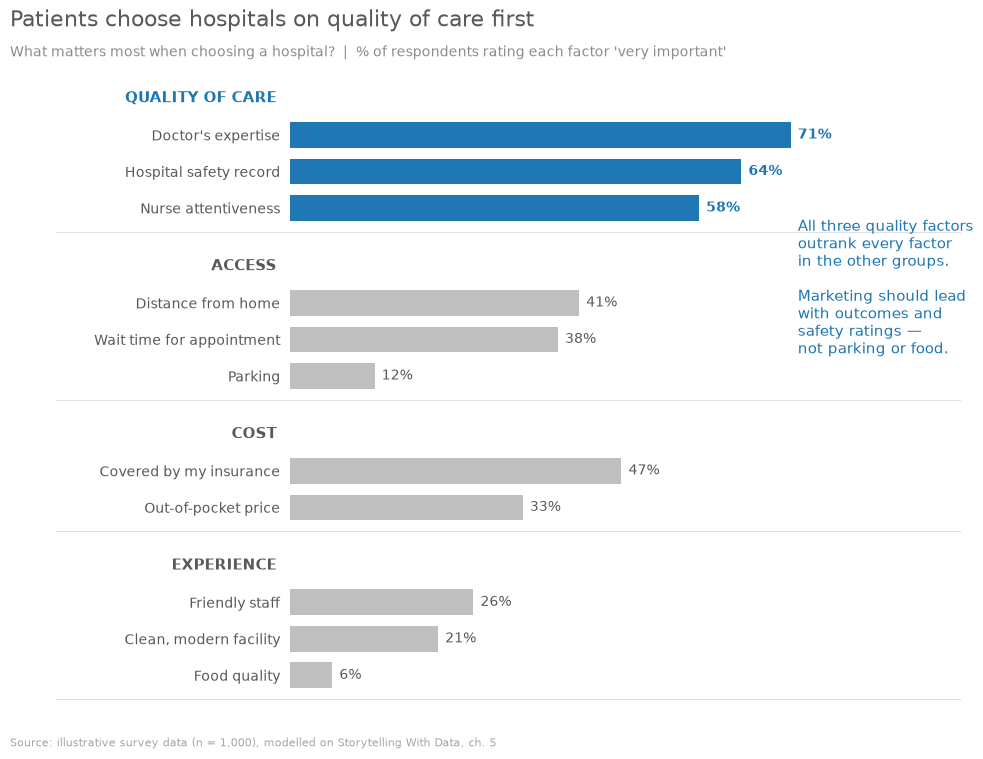

In [23]:
GRAY, DARK, ACCENT = "#BFBFBF", "#595959", "#1F77B4"

groups = {
    "QUALITY OF CARE": [("Doctor's expertise", 0.71), ("Hospital safety record", 0.64),
                        ("Nurse attentiveness", 0.58)],
    "ACCESS":          [("Distance from home", 0.41), ("Wait time for appointment", 0.38),
                        ("Parking", 0.12)],
    "COST":            [("Covered by my insurance", 0.47), ("Out-of-pocket price", 0.33)],
    "EXPERIENCE":      [("Friendly staff", 0.26), ("Clean, modern facility", 0.21),
                        ("Food quality", 0.06)],
}
highlight = "QUALITY OF CARE"

fig, ax = plt.subplots(figsize=(10, 7.5))
y, yticks, ylabels = 0, [], []
for g, items in groups.items():
    col = ACCENT if g == highlight else GRAY
    ax.text(-0.02, y, g, transform=ax.get_yaxis_transform(), ha="right", va="center",
            fontsize=10.5, fontweight="bold", color=col if g == highlight else DARK)
    y += 1
    for label, v in sorted(items, key=lambda t: -t[1]):
        ax.barh(y, v, color=col, height=0.7)
        ax.text(v + 0.01, y, f"{v:.0%}", va="center", fontsize=10,
                color=col if g == highlight else DARK, fontweight="bold" if g == highlight else "normal")
        yticks.append(y); ylabels.append(label)
        y += 1
    ax.axhline(y - 0.35, color="#E0E0E0", lw=0.8, xmin=-0.35, clip_on=False)
    y += 0.6

ax.set_yticks(yticks, ylabels, fontsize=10, color=DARK)
ax.invert_yaxis()
ax.set_xticks([]); ax.set_xlim(0, 0.95)
for s in ax.spines.values():
    s.set_visible(False)
ax.tick_params(left=False)

fig.text(0.02, 0.97, "Patients choose hospitals on quality of care first",
         fontsize=16, color=DARK, ha="left")
fig.text(0.02, 0.93, "What matters most when choosing a hospital?  |  % of respondents rating each factor 'very important'",
         fontsize=10, color="#8C8C8C", ha="left")
ax.text(0.72, 5.2, "All three quality factors\noutrank every factor\nin the other groups.\n\n"
        "Marketing should lead\nwith outcomes and\nsafety ratings —\nnot parking or food.",
        fontsize=10.5, color=ACCENT, va="center")
fig.text(0.02, 0.01, "Source: illustrative survey data (n = 1,000), modelled on Storytelling With Data, ch. 5",
         fontsize=8, color="#A6A6A6")
plt.subplots_adjust(left=0.30, top=0.88, bottom=0.05, right=0.97)
plt.show()

**Design choices borrowed from the book:** super‑category headers group 11 bars into 4 meaningful chunks; one colour draws attention to the group the story is about while everything else is pushed to grey; direct labels replace the axis; the clutter (border, gridlines, tick marks) is gone; the title states the takeaway, and the annotation sits right next to the data it explains.